In [1]:
import matplotlib.pyplot as plt
print("it works")


it works


In [2]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df = pd.read_csv('HRDataset_v14.csv')
print("shape:", df.shape)
df.head()

shape: (311, 34)


,EmpID,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,PerfScoreID,Unnamed: 7,Salary,Unnamed: 9,PositionID,Position,State,Unnamed: 13,Unnamed: 14,Sex,MaritalDesc,CitizenDesc,Unnamed: 18,DateofHire,DateofHire.1,TermReason,EmploymentStatus,Department,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,10026,NaN,NaN,NaN,NaN,NaN,4,NaN,62506,NaN,19,Production Technician I,MA,NaN,NaN,M,Single,US Citizen,NaN,7/5/2011,8/5/2011,N/A-StillEmployed,Active,Production,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,10084,NaN,NaN,NaN,NaN,NaN,3,NaN,104437,NaN,27,Sr. DBA,MA,NaN,NaN,M,Married,US Citizen,NaN,3/30/2015,3/30/2016,career change,Voluntarily Terminated,IT/IS,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,10196,NaN,NaN,NaN,NaN,NaN,3,NaN,64955,NaN,20,Production Technician II,MA,NaN,NaN,F,Married,US Citizen,NaN,7/5/2011,8/5/2011,hours,Voluntarily Terminated,Production,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,10088,NaN,NaN,NaN,NaN,NaN,3,NaN,64991,NaN,19,Production Technician I,MA,NaN,NaN,F,Married,US Citizen,NaN,1/7/2008,2/7/2008,N/A-StillEmployed,Active,Production,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,10069,NaN,NaN,NaN,NaN,NaN,3,NaN,50825,NaN,19,Production Technician I,MA,NaN,NaN,F,Divorced,US Citizen,NaN,7/11/2011,8/11/2011,return to school,Voluntarily Terminated,Production,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [3]:
missing=df.isnull().sum()
print(missing[missing >0])

Unnamed: 1     311
Unnamed: 2     311
Unnamed: 3     311
Unnamed: 4     311
Unnamed: 5     311
Unnamed: 7     311
Unnamed: 9     311
Unnamed: 13    311
Unnamed: 14    311
Unnamed: 18    311
ManagerID        8
dtype: int64


In [4]:
print(list(df.columns))

['EmpID', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'PerfScoreID', 'Unnamed: 7', 'Salary', 'Unnamed: 9', 'PositionID', 'Position', 'State', 'Unnamed: 13', 'Unnamed: 14', 'Sex', 'MaritalDesc', 'CitizenDesc', 'Unnamed: 18', 'DateofHire', 'DateofHire.1', 'TermReason', 'EmploymentStatus', 'Department', 'ManagerName', 'ManagerID', 'RecruitmentSource', 'PerformanceScore', 'EngagementSurvey', 'EmpSatisfaction', 'SpecialProjectsCount', 'LastPerformanceReview_Date', 'DaysLateLast30', 'Absences']


In [5]:
for i, col in enumerate(df.columns):
  print(i, col)

0 EmpID
1 Unnamed: 1
2 Unnamed: 2
3 Unnamed: 3
4 Unnamed: 4
5 Unnamed: 5
6 PerfScoreID
7 Unnamed: 7
8 Salary
9 Unnamed: 9
10 PositionID
11 Position
12 State
13 Unnamed: 13
14 Unnamed: 14
15 Sex
16 MaritalDesc
17 CitizenDesc
18 Unnamed: 18
19 DateofHire
20 DateofHire.1
21 TermReason
22 EmploymentStatus
23 Department
24 ManagerName
25 ManagerID
26 RecruitmentSource
27 PerformanceScore
28 EngagementSurvey
29 EmpSatisfaction
30 SpecialProjectsCount
31 LastPerformanceReview_Date
32 DaysLateLast30
33 Absences


In [6]:
print(df[['EmpID', 'DateofHire', 'DateofHire.1', 'EmploymentStatus']].head(10).to_string())

   EmpID  DateofHire DateofHire.1        EmploymentStatus
0  10026    7/5/2011     8/5/2011                  Active
1  10084   3/30/2015    3/30/2016  Voluntarily Terminated
2  10196    7/5/2011     8/5/2011  Voluntarily Terminated
3  10088    1/7/2008     2/7/2008                  Active
4  10069   7/11/2011    8/11/2011  Voluntarily Terminated
5  10002    1/9/2012     2/9/2012                  Active
6  10194  11/10/2014   12/10/2014                  Active
7  10062   9/30/2013    9/30/2014                  Active
8  10114    7/6/2009     8/6/2009                  Active
9  10250    1/5/2015     2/5/2015                  Active


## Cleaning Identification

**Issue 1 — Empty placeholder columns:** 10 columns (Unnamed: 1, 2, 3, 4, 5, 7, 9, 13, 14, 18) are completely empty in all 311 rows. This likely happened because the original file's header row had more comma-separated fields than the data itself carries — columns like employee name or gender may have been stripped out of this copy, leaving blank placeholder columns behind. These will be dropped since they add nothing to the analysis.

**Issue 2 — Duplicated, mislabeled column:** The header literally contains "DateofHire" twice. Pandas auto-renamed the second one to "DateofHire.1" to avoid a clash. Checking the data shows every Active employee (someone never terminated) still has a value in this column — which rules out it being a real "date of termination," since that should be blank for anyone still employed. Since its true meaning can't be verified, this column will be dropped rather than used under a false assumption.

In [7]:
df_clean = df.copy()

empty_cols = [c for c in df_clean.columns if df_clean[c].isnull().all()]
df_clean = df_clean.drop(columns=empty_cols)

df_clean = df_clean.drop(columns=['DateofHire.1'])

print("Dropped", len(empty_cols), "empty columns, plus DateofHire.1")
print("New shape:", df_clean.shape)

Dropped 10 empty columns, plus DateofHire.1
New shape: (311, 23)


In [8]:
print("Sex values:", [repr(v) for v in df_clean['Sex'].unique()])
print("Department values:", [repr(v) for v in df_clean['Department'].unique()])

Sex values: ["'M '", "'F'"]
Department values: ["'Production       '", "'IT/IS'", "'Software Engineering'", "'Admin Offices'", "'Sales'", "'Executive Office'"]


In [9]:
text_cols = df_clean.select_dtypes(include='object').columns.tolist()
for c in text_cols:
    df_clean[c] = df_clean[c].astype(str).str.strip()

print("Sex after cleaning:", [repr(v) for v in df_clean['Sex'].unique()])
print("Department after cleaning:", [repr(v) for v in df_clean['Department'].unique()])

Sex after cleaning: ["'M'", "'F'"]
Department after cleaning: ["'Production'", "'IT/IS'", "'Software Engineering'", "'Admin Offices'", "'Sales'", "'Executive Office'"]


In [10]:
missing_managers = df_clean[df_clean['ManagerID'].isnull()]
print(missing_managers[['EmpID', 'ManagerName', 'ManagerID']])

     EmpID     ManagerName  ManagerID
19   10277  Webster Butler        NaN
30   10184  Webster Butler        NaN
44   10154  Webster Butler        NaN
88   10136  Webster Butler        NaN
135  10214  Webster Butler        NaN
177  10077  Webster Butler        NaN
232  10011  Webster Butler        NaN
251  10071  Webster Butler        NaN


In [11]:
df_clean['ManagerID'] = df_clean['ManagerID'].astype('Int64')
print(df_clean['ManagerID'].dtype)
print("Still missing:", df_clean['ManagerID'].isnull().sum())

Int64
Still missing: 8


## Cleaning Execution

The following fixes were applied to address the issues identified above:
- Dropped the 10 completely empty placeholder columns
- Dropped `DateofHire.1` (the mislabeled, unverifiable duplicate date column)
- Stripped whitespace from every text column (fixed inconsistencies like `'M '` vs `'F'`, and trailing spaces in `Department`)
- Converted `ManagerID` to a proper integer type, keeping its 8 genuinely missing values as missing rather than guessing a value — since the missingness is tied specifically to employees managed by Webster Butler, it looks like a structural data-entry gap rather than random error, and inventing an ID would misrepresent the data.

After these fixes, `df_clean` has 311 rows and 23 columns, with no unexplained missing values remaining.

In [12]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate EmpIDs:", df_clean['EmpID'].duplicated().sum())
print()
df_clean.info()

Duplicate rows: 0
Duplicate EmpIDs: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   EmpID                       311 non-null    int64  
 1   PerfScoreID                 311 non-null    int64  
 2   Salary                      311 non-null    int64  
 3   PositionID                  311 non-null    int64  
 4   Position                    311 non-null    object 
 5   State                       311 non-null    object 
 6   Sex                         311 non-null    object 
 7   MaritalDesc                 311 non-null    object 
 8   CitizenDesc                 311 non-null    object 
 9   DateofHire                  311 non-null    object 
 10  TermReason                  311 non-null    object 
 11  EmploymentStatus            311 non-null    object 
 12  Department                  311 non-null    object 
 

In [13]:
df_clean['DateofHire'] = pd.to_datetime(df_clean['DateofHire'], format='%m/%d/%Y')
df_clean['LastPerformanceReview_Date'] = pd.to_datetime(df_clean['LastPerformanceReview_Date'], format='%m/%d/%Y')

print(df_clean[['DateofHire', 'LastPerformanceReview_Date']].dtypes)

DateofHire                    datetime64[ns]
LastPerformanceReview_Date    datetime64[ns]
dtype: object


Final re-check after all cleaning steps: 311 rows, 23 columns, 0 duplicate rows, 0 duplicate EmpIDs, both date columns properly converted to datetime type. The only remaining missing values are the 8 genuinely-missing ManagerID entries documented above — this is expected, not an oversight.

##Exploratory Data Analysis

In [14]:
df_clean.describe()

,EmpID,PerfScoreID,Salary,PositionID,DateofHire,ManagerID,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
count,311.000000,311.000000,311.000000,311.000000,311,303.0,311.000000,311.000000,311.000000,311,311.000000,311.000000
mean,10156.000000,2.977492,69020.684887,16.845659,2013-02-03 22:50:32.797427712,14.570957,4.110000,3.890675,1.218650,2017-09-10 21:17:56.527331072,0.414791,10.237942
min,10001.000000,1.000000,45046.000000,1.000000,2006-01-09 00:00:00,1.0,1.120000,1.000000,0.000000,2010-07-14 00:00:00,0.000000,1.000000
25%,10078.500000,3.000000,55501.500000,18.000000,2011-07-11 00:00:00,10.0,3.690000,3.000000,0.000000,2016-03-19 12:00:00,0.000000,5.000000
50%,10156.000000,3.000000,62810.000000,19.000000,2013-02-18 00:00:00,15.0,4.280000,4.000000,0.000000,2019-01-16 00:00:00,0.000000,10.000000
75%,10233.500000,3.000000,72036.000000,20.000000,2014-09-23 12:00:00,19.0,4.700000,5.000000,0.000000,2019-02-04 00:00:00,0.000000,15.000000
max,10311.000000,4.000000,250000.000000,30.000000,2018-07-09 00:00:00,39.0,5.000000,5.000000,8.000000,2019-02-28 00:00:00,6.000000,20.000000
std,89.922189,0.587072,25156.636930,6.223419,NaN,8.078306,0.789938,0.909241,2.349421,NaN,1.294519,5.852596


In [15]:
df_clean.nlargest(5, 'Salary')[['EmpID', 'Position', 'Department', 'Salary']]

,EmpID,Position,Department,Salary
150,10089,President & CEO,Executive Office,250000
308,10010,CIO,IT/IS,220450
131,10272,Director of Sales,Sales,180000
96,10015,IT Director,IT/IS,178000
55,10019,Director of Operations,Production,170500


**Checked: Salary outlier.** The maximum salary ($250,000) initially looked extreme against the average (~$69,021), but cross-checking against `Position` confirms it belongs to the President & CEO, followed by other senior roles (CIO, Director of Sales, IT Director, Director of Operations). This is a legitimate seniority-based pay structure, not a data entry error, so these values are kept as-is.

In [16]:
print(df_clean['Department'].value_counts())
print()
print(df_clean['EmploymentStatus'].value_counts())

Department
Production              209
IT/IS                    50
Sales                    31
Software Engineering     11
Admin Offices             9
Executive Office          1
Name: count, dtype: int64

EmploymentStatus
Active                    207
Voluntarily Terminated     88
Terminated for Cause       16
Name: count, dtype: int64


In [17]:
attrition_rate = (df_clean['EmploymentStatus'] != 'Active').mean() * 100
print(f"Overall attrition rate: {attrition_rate:.1f}%")

Overall attrition rate: 33.4%


In [18]:
attrition_by_dept = df_clean.groupby('Department')['EmploymentStatus'].apply(lambda s: round((s != 'Active').mean() * 100, 1))
print(attrition_by_dept.sort_values(ascending=False))

Department
Production              39.7
Software Engineering    36.4
Admin Offices           22.2
IT/IS                   20.0
Sales                   16.1
Executive Office         0.0
Name: EmploymentStatus, dtype: float64


In [19]:
avg_salary_by_dept = df_clean.groupby('Department')['Salary'].mean().round(0).sort_values(ascending=False)
print(avg_salary_by_dept)

Department
Executive Office        250000.0
IT/IS                    97065.0
Software Engineering     94989.0
Admin Offices            71792.0
Sales                    69061.0
Production               59954.0
Name: Salary, dtype: float64


**Finding: Attrition tracks with pay across departments.** Production has both the lowest average salary ($59,954) and the highest attrition rate (39.7%) of any department. Software Engineering follows a similar pattern — second-lowest pay, second-highest attrition (36.4%). Executive Office and IT/IS, the highest-paid departments, have the lowest attrition. This isn't proof that pay alone drives attrition, but it's a consistent enough pattern to flag as a starting point for a real retention conversation.

In [20]:
print(df_clean['PerformanceScore'].value_counts())
print()
print(df_clean['RecruitmentSource'].value_counts())

PerformanceScore
Fully Meets          243
Exceeds               37
Needs Improvement     18
PIP                   13
Name: count, dtype: int64

RecruitmentSource
Indeed                     87
LinkedIn                   76
Google Search              49
Employee Referral          31
Diversity Job Fair         29
CareerBuilder              23
Website                    13
Other                       2
On-line Web application     1
Name: count, dtype: int64


In [21]:
attrition_by_RecruitmentSource = df_clean.groupby('RecruitmentSource')['EmploymentStatus'].apply(lambda s: round((s != 'Active').mean() * 100, 1))
print(attrition_by_RecruitmentSource.sort_values(ascending=False))

RecruitmentSource
On-line Web application    100.0
Google Search               61.2
Diversity Job Fair          55.2
Other                       50.0
CareerBuilder               47.8
Indeed                      24.1
LinkedIn                    23.7
Employee Referral           16.1
Website                      7.7
Name: EmploymentStatus, dtype: float64


**Finding: Referral and website-sourced hires stay longer.** Website-sourced hires have the lowest attrition rate at 7.7%, followed by Employee Referral at 16.1% — both meaningfully lower than major sources like Indeed (24.1%) or LinkedIn (23.7%). This likely comes down to trust and realistic expectations: someone referred by a current employee, or who sought the company out directly, usually has a clearer picture of the role and culture before accepting, which means fewer surprises that push them to leave early. Note: "On-line Web application" shows 100% attrition, but that's based on just 1 person total, so it isn't a meaningful data point.

In [22]:
df_clean['EngagementSurvey'].corr(df_clean['DaysLateLast30'])

np.float64(-0.5852315472719383)

In [23]:
print(df_clean.columns)

Index(['EmpID', 'PerfScoreID', 'Salary', 'PositionID', 'Position', 'State',
       'Sex', 'MaritalDesc', 'CitizenDesc', 'DateofHire', 'TermReason',
       'EmploymentStatus', 'Department', 'ManagerName', 'ManagerID',
       'RecruitmentSource', 'PerformanceScore', 'EngagementSurvey',
       'EmpSatisfaction', 'SpecialProjectsCount', 'LastPerformanceReview_Date',
       'DaysLateLast30', 'Absences'],
      dtype='object')


In [24]:
df_clean['EngagementSurvey'].corr(df_clean['Absences'])

np.float64(-0.00877066057321234)

**Finding: Engagement correlates with lateness, but not with absences.** Comparing EngagementSurvey scores against lateness (DaysLateLast30) shows a correlation of -0.585 — a fairly strong negative relationship, meaning less-engaged employees tend to be late more often. By contrast, EngagementSurvey vs. full-day Absences shows almost no relationship at all (-0.008). This suggests lateness is a more meaningful early signal of disengagement than absence counts are;a manager watching for early signs of a flight risk would learn more from tracking lateness patterns than from counting days off.

In [25]:
snapshot_date = df_clean['LastPerformanceReview_Date'].max()
print(snapshot_date)

2019-02-28 00:00:00


In [26]:
df_clean['YearsSinceHire'] = (snapshot_date - df_clean['DateofHire']).dt.days / 365.25

In [27]:
df_clean[['DateofHire', 'YearsSinceHire']].head(10)

,DateofHire,YearsSinceHire
0,2011-07-05,7.652293
1,2015-03-30,3.917864
2,2011-07-05,7.652293
3,2008-01-07,11.143053
4,2011-07-11,7.635866
5,2012-01-09,7.137577
6,2014-11-10,4.301164
7,2013-09-30,5.412731
8,2009-07-06,9.648186
9,2015-01-05,4.147844


In [28]:
df_clean['YearsSinceHire'] = df_clean['YearsSinceHire'].round(1)
df_clean[['DateofHire', 'YearsSinceHire']].head(5)

,DateofHire,YearsSinceHire
0,2011-07-05,7.7
1,2015-03-30,3.9
2,2011-07-05,7.7
3,2008-01-07,11.1
4,2011-07-11,7.6


**Derived column: YearsSinceHire.** This column calculates how long each employee has been with the company, measured from their `DateofHire` up to a reference point. Since the dataset has no field indicating "today's date," the most recent value in `LastPerformanceReview_Date` was used as a stand-in "snapshot date"; it's the closest thing to "now" that the data itself provides, which is more defensible than picking an arbitrary external date.

In [29]:
df_clean['SalaryBand'] = pd.cut(
    df_clean['Salary'],
    bins=[0, 50000, 65000, 85000, float('inf')],
    labels=['Under 50K', '50K-65K', '65K-85K', '85K+']
)

In [30]:
print(df_clean['SalaryBand'].value_counts())

SalaryBand
50K-65K      164
65K-85K       66
85K+          50
Under 50K     31
Name: count, dtype: int64


In [31]:
pivot_engagement = pd.pivot_table(
    df_clean,
    values='EngagementSurvey',
    index='Department',
    columns='PerformanceScore',
    aggfunc='mean'
).round(2)

pivot_engagement

PerformanceScore,Exceeds,Fully Meets,Needs Improvement,PIP
Department,,,,
Admin Offices,NaN,4.39,NaN,NaN
Executive Office,NaN,4.83,NaN,NaN
IT/IS,4.57,4.21,2.39,1.20
Production,4.44,4.26,3.13,2.45
Sales,4.43,4.13,2.40,2.01
Software Engineering,4.75,4.14,2.10,NaN


In [32]:
pd.crosstab(df_clean['Department'], df_clean['PerformanceScore'])

PerformanceScore,Exceeds,Fully Meets,Needs Improvement,PIP
Department,,,,
Admin Offices,0,9,0,0
Executive Office,0,1,0,0
IT/IS,6,42,1,1
Production,27,159,15,8
Sales,2,24,1,4
Software Engineering,2,8,1,0


**Finding: Engagement tracks with performance.** The pivot table comparing EngagementSurvey scores across Department and PerformanceScore shows a consistent pattern: employees rated "Exceeds" or "Fully Meets" tend to have noticeably higher engagement scores (around 4.1-4.8) than those rated "Needs Improvement" or "PIP" (around 1.2-3.1), across every department. Some cells in the pivot table showed NaN rather than a number — this isn't missing data, it's because small departments like Admin Offices and Executive Office simply have zero people in certain performance categories, confirmed by cross-checking with a crosstab of actual headcounts.

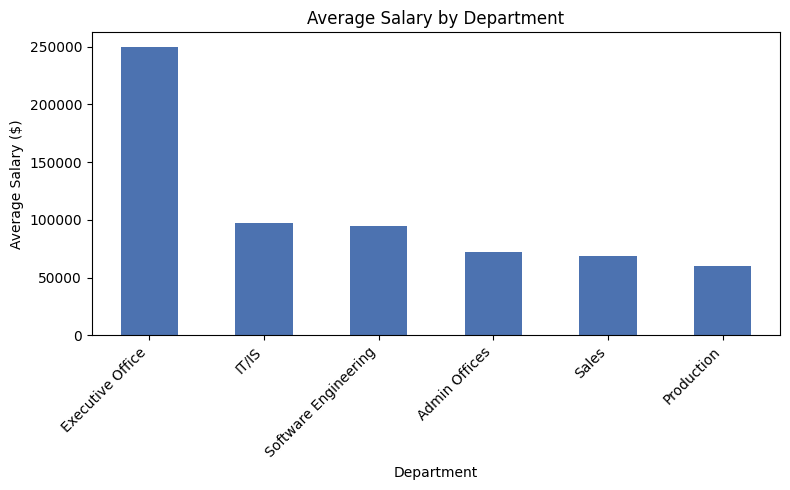

In [33]:
avg_salary_by_dept = df_clean.groupby('Department')['Salary'].mean().round(0).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8,5))
avg_salary_by_dept.plot(kind='bar', ax=ax, color='#4C72B0')
ax.set_title('Average Salary by Department')
ax.set_xlabel('Department')
ax.set_ylabel('Average Salary ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [34]:
df_clean['HireYear'] = df_clean['DateofHire'].dt.year
hires_per_year = df_clean['HireYear'].value_counts().sort_index()
print(hires_per_year)

HireYear
2006     1
2007     2
2008     3
2009     7
2010     9
2011    83
2012    45
2013    44
2014    60
2015    36
2016    14
2017     6
2018     1
Name: count, dtype: int64


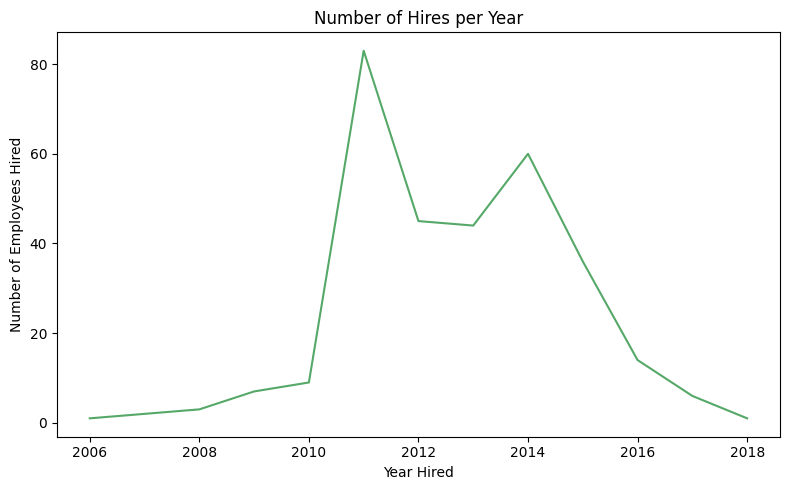

In [35]:
fig, ax = plt.subplots(figsize=(8,5))
hires_per_year.plot(kind='line', ax=ax, color='#55A868')
ax.set_title('Number of Hires per Year')
ax.set_xlabel('Year Hired')
ax.set_ylabel('Number of Employees Hired')
plt.tight_layout()
plt.show()

**Reading the hiring trend chart:** hiring is heavily concentrated around 2011-2015, with a sharp spike of 83 hires in 2011 alone, which is by far the highest of any year, followed by a steady decline down to single digits by 2017-2018. That shape, a sudden surge followed by a steady drop-off, usually points to a specific growth event (the company scaling up rapidly around 2011) rather than steady, predictable hiring year over year. This also matters for interpreting tenure: a large share of the workforce was hired in that same narrow window, so YearsSinceHire values will cluster rather than spread evenly across the years.

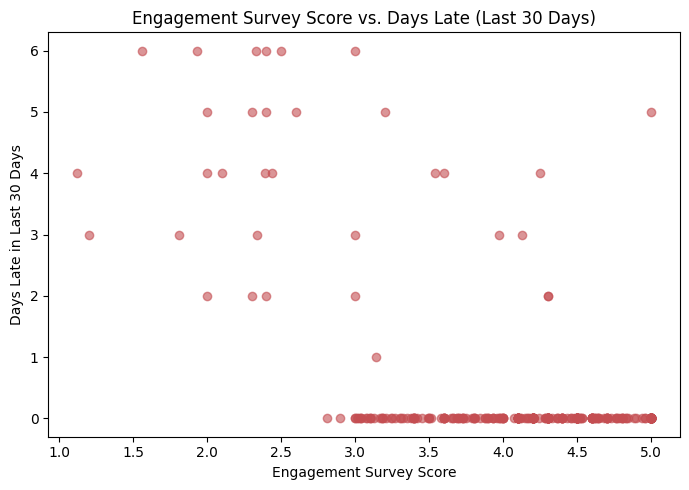

In [36]:
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(df_clean['EngagementSurvey'], df_clean['DaysLateLast30'], color='#C44E52', alpha=0.6)
ax.set_title('Engagement Survey Score vs. Days Late (Last 30 Days)')
ax.set_xlabel('Engagement Survey Score')
ax.set_ylabel('Days Late in Last 30 Days')
plt.tight_layout()
plt.show()

## INSIGHTS $ INTERPRETATION


**Finding: Attrition tracks with pay across departments.** Production has both the lowest average salary ($59,954) and the highest attrition rate (39.7%) of any department. Software Engineering follows a similar pattern — second-lowest pay, second-highest attrition (36.4%). Executive Office and IT/IS, the highest-paid departments, have the lowest attrition. This isn't proof that pay alone drives attrition, but it's a consistent enough pattern to flag as a starting point for a real retention conversation.

**Finding: Referral and website-sourced hires stay longer.** Website-sourced hires have the lowest attrition rate at 7.7%, followed by Employee Referral at 16.1% — both meaningfully lower than major sources like Indeed (24.1%) or LinkedIn (23.7%). This likely comes down to trust and realistic expectations: someone referred by a current employee, or who sought the company out directly, usually has a clearer picture of the role and culture before accepting, which means fewer surprises that push them to leave early. Note: "On-line Web application" shows 100% attrition, but that's based on just 1 person total, so it isn't a meaningful data point.

**Finding: Engagement correlates with lateness, but not with absences.** Comparing EngagementSurvey scores against lateness (DaysLateLast30) shows a correlation of -0.585 — a fairly strong negative relationship, meaning less-engaged employees tend to be late more often. By contrast, EngagementSurvey vs. full-day Absences shows almost no relationship at all (-0.008). This suggests lateness is a more meaningful early signal of disengagement than absence counts are;a manager watching for early signs of a flight risk would learn more from tracking lateness patterns than from counting days off.

**Finding: Engagement tracks with performance.** The pivot table comparing EngagementSurvey scores across Department and PerformanceScore shows a consistent pattern: employees rated "Exceeds" or "Fully Meets" tend to have noticeably higher engagement scores (around 4.1-4.8) than those rated "Needs Improvement" or "PIP" (around 1.2-3.1), across every department. Some cells in the pivot table showed NaN rather than a number — this isn't missing data, it's because small departments like Admin Offices and Executive Office simply have zero people in certain performance categories, confirmed by cross-checking with a crosstab of actual headcounts.

## FINAL SUMMARY
This notebook worked through HRDataset_v14, a 311-employee HR dataset from Kaggle. The raw data had real structural problems; empty placeholder columns, a duplicated and mislabeled date column, inconsistent text formatting, and scattered missing values — all identified and fixed with documented reasoning before any analysis began.

The clearest pattern across the analysis: attrition is uneven and tracks closely with pay and engagement. Production and Software Engineering, the lowest-paid departments, also had the highest attrition rates, while less-engaged employees showed up late significantly more often than highly engaged ones (though not more absent overall).

If this were a real business question, the recommendation would be to prioritize a retention and pay review in Production specifically, since it combines the lowest average salary with the highest attrition of any department and to use lateness patterns, not just absence counts, as an early warning signal for disengagement. This reinforces a broader point: proper structure and attention paid to people, not just operations, matters for retention.